In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("solar_system.csv")
df

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3
5,Rotation Period (hours),1407.6,-5832.5,23.9,655.7,24.6,9.9,10.7,-17.2,16.1,-153.3
6,Length of Day (hours),4222.6,2802.0,24.0,708.7,24.7,9.9,10.7,17.2,16.1,153.3
7,Distance from Sun (10^6 km),57.9,108.2,149.6,0.384,228.0,778.5,1432.0,2867.0,4515.0,5906.4
8,Perihelion (10^6 km),46.0,107.5,147.1,0.363,206.7,740.6,1357.6,2732.7,4471.1,4436.8
9,Aphelion (10^6 km),69.8,108.9,152.1,0.406,249.3,816.4,1506.5,3001.4,4558.9,7375.9


In [3]:
df.shape # 20 rows, 11 columns
print(df.head())
print(df.tail())
print(df.columns)
print(df["Attribute"])

                Attribute Mercury  Venus  Earth   Moon   Mars Jupiter  Saturn  \
0          Mass (10^24kg)   0.330   4.87   5.97  0.073  0.642    1898     568   
1           Diameter (km)    4879  12104  12756   3475   6792  142984  120536   
2        Density (kg/m^3)    5429   5243   5514   3340   3934    1326     687   
3         Gravity (m/s^2)     3.7    8.9    9.8    1.6    3.7    23.1     9.0   
4  Escape Velocity (km/s)     4.3   10.4   11.2    2.4    5.0    59.5    35.5   

  Uranus Neptune   Pluto  
0   86.8     102  0.0130  
1  51118   49528    2376  
2   1270    1638    1850  
3    8.7    11.0     0.7  
4   21.3    23.5     1.3  
                  Attribute Mercury Venus Earth Moon  Mars  Jupiter   Saturn  \
15     Mean Temperature (C)     167   464    15  -20   -65     -110     -140   
16  Surface Pressure (bars)       0    92     1    0  0.01  Unknown  Unknown   
17          Number of Moons       0     0     1    0     2       95      274   
18             Ring System?    

In [4]:
peri = df.iloc[8,1:].astype(float)
ap = df.iloc[9,1:].astype(float)
orb_per = df.iloc[10,1:].astype(float)

perihelion = point where the orbiting body is closest to the thing it orbits
aphelion = point where the orbiting body is farthest from the thing it orbits
semi-major axis = the length between the perihelion and aphelion that is along the longest part of the ellipse

In [5]:
semi_maj = (peri + ap) / 2
df = pd.concat([df, semi_maj.to_frame().T], ignore_index=True)
df.loc[20, "Attribute"] = "Semi-Major Axis (10^6 km)"

df

,Attribute,Mercury,Venus,Earth,Moon,Mars,Jupiter,Saturn,Uranus,Neptune,Pluto
0,Mass (10^24kg),0.330,4.87,5.97,0.073,0.642,1898,568,86.8,102,0.0130
1,Diameter (km),4879,12104,12756,3475,6792,142984,120536,51118,49528,2376
2,Density (kg/m^3),5429,5243,5514,3340,3934,1326,687,1270,1638,1850
3,Gravity (m/s^2),3.7,8.9,9.8,1.6,3.7,23.1,9.0,8.7,11.0,0.7
4,Escape Velocity (km/s),4.3,10.4,11.2,2.4,5.0,59.5,35.5,21.3,23.5,1.3
5,Rotation Period (hours),1407.6,-5832.5,23.9,655.7,24.6,9.9,10.7,-17.2,16.1,-153.3
6,Length of Day (hours),4222.6,2802.0,24.0,708.7,24.7,9.9,10.7,17.2,16.1,153.3
7,Distance from Sun (10^6 km),57.9,108.2,149.6,0.384,228.0,778.5,1432.0,2867.0,4515.0,5906.4
8,Perihelion (10^6 km),46.0,107.5,147.1,0.363,206.7,740.6,1357.6,2732.7,4471.1,4436.8
9,Aphelion (10^6 km),69.8,108.9,152.1,0.406,249.3,816.4,1506.5,3001.4,4558.9,7375.9


In [7]:
print(df.shape) #21 rows, 11 columns

(21, 11)


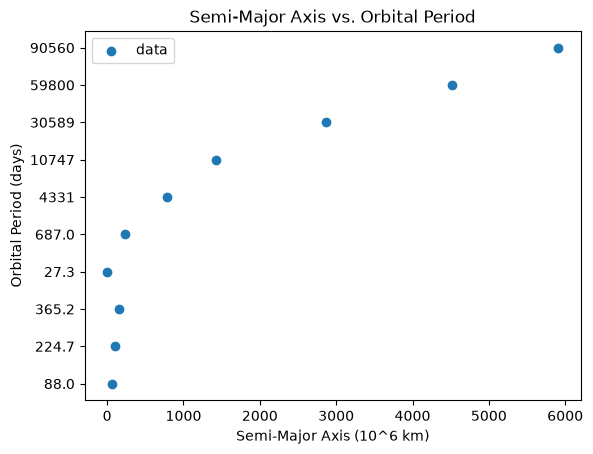

In [29]:
a = pd.to_numeric(df.iloc[20, 1:])
p = pd.to_numeric(df.iloc[10, 1:])

plt.figure()
plt.scatter(df.iloc[20,1:], df.iloc[10,1:], label = "data")
plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title("Semi-Major Axis vs. Orbital Period")
plt.legend()
plt.show()

In [32]:
def keplers_third_law(a, m):
    return m * a ** 1.5

def fit_model(a,p):
    popt, pcov = curve_fit(keplers_third_law, a, p)
    m_fit = popt[0]
    print(f"Fitted model: T = {m_fit:.2f} * a^1.5")
    
    residuals = p - keplers_third_law(a, m_fit)
    chi2 = np.sum((residuals)**2)
    dof = len(p) - len(popt)
    chi2_reduced = chi2 / dof
    print(f"Reduced chi-squared: {chi2_reduced:.2f}")
    return m_fit, chi2_reduced

fit_model(a, p)

Fitted model: T = 0.20 * a^1.5
Reduced chi-squared: 41276.71


(np.float64(0.19879981918623565), np.float64(41276.70608939402))

Fitted model: T = 0.20 * a^1.5
Reduced chi-squared: 41276.71


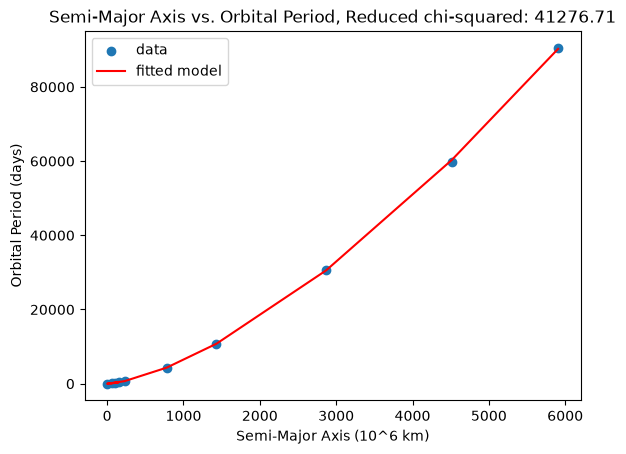

In [36]:
m_fit, chi2_reduced = fit_model(a, p)
plt.figure()
plt.scatter(a, p, label = "data")
plt.plot(a, m_fit * a**1.5, color="red", label = "fitted model")
plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title(f"Semi-Major Axis vs. Orbital Period, Reduced chi-squared: {chi2_reduced:.2f}")
plt.legend()
plt.show()

In [37]:
df.to_csv("kepler.csv", index=False)